## Distributed Grep - Performance testing

This notebook will provide an insight into the performance tests carried out on my distributed grep program showing how changing different metrics on the cluster like the number of executors, number of cores per executor, memory and dataset size would change the runtime of the spark job.

I set a stable key word, 'queen', within the distributed grep program so that there were not many different outputs that would skew the data I found.

In [2]:
import pandas as pd

performanceData_executors =  pd.read_excel("FYP_performance_testing.xlsx", "DistributedGrep perf - Executor")

performanceData_executors

,num_executors,executor_cores,executor_memory,runtime_seconds
0,1,1,4G,17384
1,2,1,4G,7552
2,3,1,4G,4954
3,4,1,4G,3585
4,5,1,4G,2924
5,6,1,4G,2410
6,7,1,4G,2154
7,8,1,4G,1859
8,9,1,4G,1785
9,10,1,4G,1646


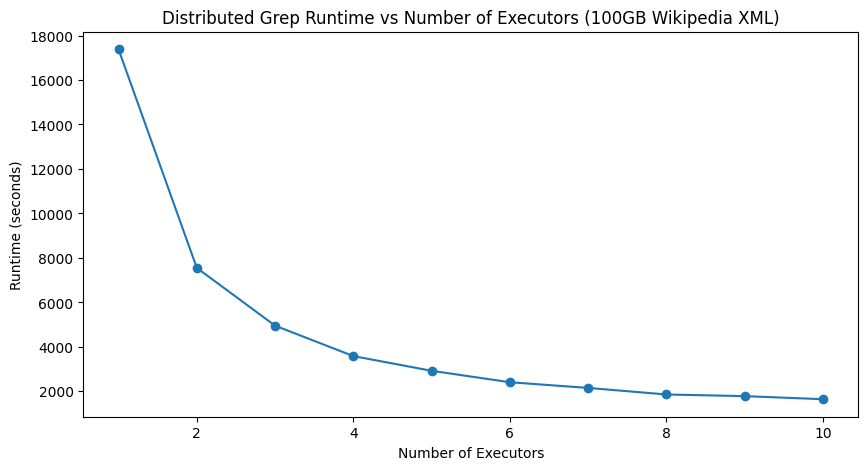

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10,5))

plt.plot(performanceData_executors["num_executors"],
         performanceData_executors["runtime_seconds"],
         marker="o")

plt.title("Distributed Grep Runtime vs Number of Executors (100GB Wikipedia XML)")
plt.xlabel("Number of Executors")
plt.ylabel("Runtime (seconds)")

plt.show()

## Break Down of Results - executors:

### Large decrease in the runtime

- The performance improvement from adding just one more executor is significant
- As more are added the rate at which the runtime improves decreases
- The runtime then seems to plataeu showing that adding more executors is not changing much

### Speedup Scaling - diminishing returns

- There are a number of sequential computations that must occur that must take place and adding more executors will not be as impactful

In [6]:
performanceData_dataset = pd.read_excel("FYP_performance_testing.xlsx", "DistributedGrep - Datasets")

performanceData_dataset

,Dataset_GB,num_executor,executor_cores,executor_mem,driver_mem,runtime_seconds
0,10,6,4,4G,4G,95
1,20,6,4,4G,4G,151
2,30,6,4,4G,4G,222
3,40,6,4,4G,4G,302
4,50,6,4,4G,4G,343
5,60,6,4,4G,4G,432
6,70,6,4,4G,4G,503
7,80,6,4,4G,4G,565
8,90,6,4,4G,4G,637
9,100,6,4,4G,4G,696


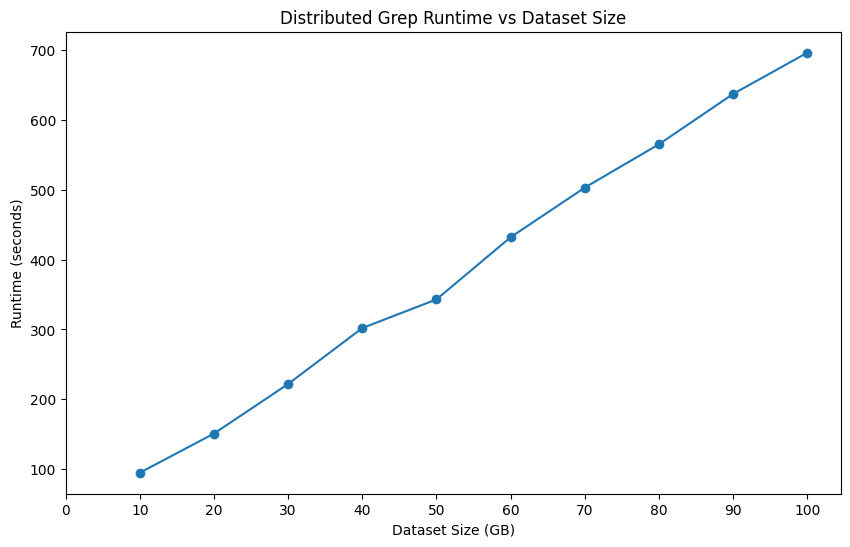

In [17]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize = (10,6))

plt.plot(performanceData_dataset["Dataset_GB"],
         performanceData_dataset["runtime_seconds"],
         marker="o")

plt.title("Distributed Grep Runtime vs Dataset Size")
plt.xlabel("Dataset Size (GB)")
plt.ylabel("Runtime (seconds)")
plt.xticks(np.arange(0, 101, 10))

plt.show()

## Break Down of Results - datasets

### Near-linear scaling
- Scaling the amount of data roughly increases the amount of time taken to complete the job
- The rate of growth is consistent and provides a similar throughput while scaling the data size

In [19]:
performanceData_memory = pd.read_excel("FYP_performance_testing.xlsx", "DistributedGrep - Memory")

performanceData_memory

,num_executors,executor_cores,executor_memory,total_executor_memory,runtime_seconds
0,6,4,1G,6G,843
1,6,4,2G,12G,853
2,6,4,4G,24G,656
3,6,4,6G,36G,796
4,6,4,8G,48G,797
5,6,4,10G,60G,690


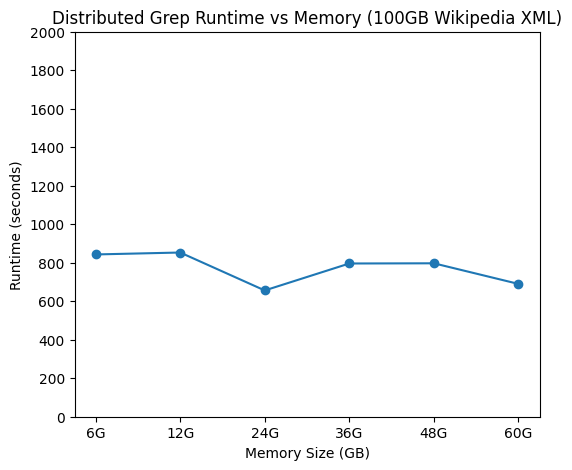

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize = (6,5))

plt.plot(performanceData_memory["total_executor_memory"],
         performanceData_memory["runtime_seconds"],
         marker="o")

plt.title("Distributed Grep Runtime vs Memory (100GB Wikipedia XML)")
plt.xlabel("Memory Size (GB)")
plt.ylabel("Runtime (seconds)")
plt.yticks(np.arange(0, 2001, 200))
plt.show()


## Break Down of Results - memory:

### Program is not bound by memory

- Changing only the memory during this experiment (other configurations kept the same)
- Adding memory to the Spark job does not significantly effect the runtime.
- The bottlenecks come from other aspects:
    - the level of parallelism
    - the I/O speeds
    - sequential aspects of the job
